# Waste to Value — RF-DETR-M_Model (Colab)

This notebook loads our trained **RF-DETR-M** garbage detection model and evaluates it on the re-split test set.

**Model:** RF-DETR-M (`rfdetr==1.11.2`), checkpoint `checkpoint_best_total.pth`
**Data:** `garbage_resplit` — test split (1,569 images), 6 classes:
BIODEGRADABLE, CARDBOARD, GLASS, METAL, PAPER, PLASTIC
**Decision threshold:** 0.55 (frozen on the validation set)

**Steps**
1. Setup: install packages and connect to Kaggle
2. Download the trained model and dataset from Kaggle
3. Load the model and run a quick test
4. Evaluate on the test set

## 1. Getting the Data

This notebook uses two Kaggle data sources, downloaded automatically with `kagglehub`:

| Source | Kaggle ID | Purpose |
|---|---|---|
| Garbage Detection – 6 Waste Categories | `viswaprakash1990/garbage-detection` | Original images and YOLO labels |
| resplit | `afnanmgs/resplit` | `resplit_assignment.csv` — assigns each image to train / validation / test |

**Before running:** log in with your own Kaggle API token in the cell below
(Kaggle → Settings → API → Create New Token).

The re-split is rebuilt from the original dataset using the assignment file, so the
test set is identical to the one used on Kaggle (1,569 images).

In [2]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


Kaggle credentials set.
Kaggle credentials successfully validated.


In [3]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

viswaprakash1990_garbage_detection_path = kagglehub.dataset_download('viswaprakash1990/garbage-detection')
afnanmgs_resplit_path = kagglehub.dataset_download('afnanmgs/resplit')

print('Data source import complete.')


100%|██████████| 191M/191M [00:01<00:00, 105MB/s]

Extracting files...


100%|██████████| 83.8k/83.8k [00:00<00:00, 45.1MB/s]

Extracting files...
Data source import complete.


In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [5]:
import kagglehub
from pathlib import Path

rs = Path(kagglehub.dataset_download("afnanmgs/resplit"))
print("Downloaded to:", rs)

ASSIGN = next(rs.rglob("resplit_assignment.csv"))
print("ASSIGN =", ASSIGN)

Downloaded to: /root/.cache/kagglehub/datasets/afnanmgs/resplit/versions/1
ASSIGN = /root/.cache/kagglehub/datasets/afnanmgs/resplit/versions/1/resplit_assignment.csv


## 2. Re-splitting the Data

The original dataset's split was replaced with a new train / validation / test split.
Each image's split is defined in `resplit_assignment.csv`,
so the split is fixed and reproducible.

The cell below rebuilds the `garbage_resplit` folder by copying each image and its
label from the original dataset into the split listed in the assignment file.

| Split | Images | Used for |
|---|---|---|
| Train | [7327] | Training the model |
| Validation | [1571] | Choosing the decision threshold (0.55) |
| Test | 1,569 | Final evaluation only |

In [6]:
import kagglehub
from pathlib import Path

# Download both data sources (works after kagglehub.login())
ds = Path(kagglehub.dataset_download("viswaprakash1990/garbage-detection"))
rs = Path(kagglehub.dataset_download("afnanmgs/resplit"))

SRC = ds / "GARBAGE CLASSIFICATION"
assert (SRC / "train" / "images").is_dir(), f"Dataset not found: {SRC}"

ASSIGN = next(rs.rglob("resplit_assignment.csv"))
print('Dataset:', SRC, '| Assignment:', ASSIGN)

Dataset: /root/.cache/kagglehub/datasets/viswaprakash1990/garbage-detection/versions/1/GARBAGE CLASSIFICATION | Assignment: /root/.cache/kagglehub/datasets/afnanmgs/resplit/versions/1/resplit_assignment.csv


In [7]:
from pathlib import Path

found = [p for root in [Path("/content"), Path("/kaggle/working"), Path("/kaggle")]
         if root.exists()
         for p in root.rglob("garbage_resplit") if p.is_dir()]
print("Re-split folders found:", found)

for folder in found:
    print("\n", folder)
    for s in ["train", "valid", "val", "test"]:
        d = folder / s / "images"
        if d.exists():
            print(f"  {s}: {len(list(d.glob('*')))} images")

Re-split folders found: []


## 2. Training

The RF-DETR-M model was trained on Kaggle (GPU T4 x2) with `rfdetr==1.11.2`
on the re-split training set, for 20 epochs (epochs 0–19).

**Training is skipped in this notebook** to save time. The training code is kept
below for reference, and the trained checkpoint (`checkpoint_best_total.pth`)
is loaded in the next section.

Note: validation loss was not logged during training (`compute_val_loss='auto'`),
so model behaviour is assessed with validation mAP and test-set evaluation.

In [8]:
import subprocess, sys, importlib
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rfdetr[train,loggers]'], check=True)
importlib.invalidate_caches()
for mod in ['rfdetr', 'vernier', 'faster_coco_eval', 'pytorch_lightning']:
    assert importlib.util.find_spec(mod), f'MISSING: {mod}'
print('All training packages present')

All training packages present


In [ ]:
import shutil, yaml
import numpy as np, pandas as pd
from pathlib import Path

# ===== 2. TRAIN =====
from rfdetr import RFDETRMedium
import torch
print('GPU:', torch.cuda.get_device_name(0))

DATA = str(OUT_DATA)
OUT  = "/kaggle/working/rfdetr_m_B"
RESUME = Path(OUT) / "checkpoint.pth"
kw = {"resume": str(RESUME)} if RESUME.exists() else {}

model = RFDETRMedium()
model.train(
    dataset_dir=DATA,
    output_dir=OUT,
    epochs=150,
    early_stopping=True,
    early_stopping_patience=10,
    optimizer="adamw",
    weight_decay=5e-4,
    batch_size=4, grad_accum_steps=4,
    lr=1e-4, lr_encoder=1.5e-4,
    lr_scheduler_kwargs={"lr_drop": 40},
    seed=0,
    best_model_metric="map",
    log_per_class_metrics=True,
    **kw,
)

## 3. Evaluation

The trained model is evaluated on the **re-split test set (1,569 images)**, which was
not used for training or threshold selection.

**Metrics.** Precision, recall and F1 are computed at IoU 0.50 using the frozen
threshold. mAP@50-95 follows the COCO standard. 95% confidence intervals are
obtained by bootstrap resampling of test images.


In [11]:
from pathlib import Path
for root in [Path("/content"), Path("/kaggle/working"), Path("/kaggle"), Path("/tmp")]:
    if root.exists():
        for p in root.rglob("images"):
            if p.is_dir() and "garbage-detection" not in str(p):
                print(p, len(list(p.glob("*"))))

In [12]:
import kagglehub
from pathlib import Path

ckpt = Path(kagglehub.notebook_output_download(
    "afnanmgs/rf-detr-m-resplitting",
    path="rfdetr_m_B/checkpoint_best_total.pth",
    force_download=True))

OUT = ckpt.parent
print("OUT =", OUT)
print("Checkpoint exists:", (OUT / "checkpoint_best_total.pth").exists())

100%|██████████| 128M/128M [00:12<00:00, 10.5MB/s]

OUT = /root/.cache/kagglehub/notebooks/afnanmgs/rf-detr-m-resplitting/output/versions/1/rfdetr_m_B
Checkpoint exists: True


In [13]:
import pandas as pd
a = pd.read_csv(ASSIGN)
print(a.shape)
print(a.head())
print(a.iloc[:, -1].value_counts())

(3140, 4)
                                               image                  group  \
0  biodegradable1000_jpg.rf.9407ff66b4ccd9f8eb554...  biodegradable1000_jpg   
1  biodegradable1004_jpg.rf.645d319975e53c260b201...  biodegradable1004_jpg   
2  biodegradable1005_jpg.rf.b7b1be167f526345b5969...  biodegradable1005_jpg   
3  biodegradable1014_jpg.rf.6c7191185080662606b4a...  biodegradable1014_jpg   
4  biodegradable1020_jpg.rf.ae69eadc714124b08e260...  biodegradable1020_jpg   

  orig_split new_split  
0      valid      test  
1      valid      test  
2      valid     valid  
3      valid      test  
4      valid     valid  
new_split
valid    1571
test     1569
Name: count, dtype: int64


In [14]:
#Resplit_data_csv-uploaded in colab
import pandas as pd
from pathlib import Path

csv = next(Path("/content").glob("*.csv"))
a = pd.read_csv(csv)
print("File:", csv.name, "| rows:", len(a))
print("Columns:", list(a.columns))
print(a.head(5).to_string())

# value counts of every column that looks like a split
for c in a.columns:
    vals = a[c].astype(str).str.lower().unique()
    if len(vals) <= 10:
        print(f"\n{c}:"); print(a[c].value_counts())

File: resplit_assignment.csv | rows: 3140
Columns: ['image', 'group', 'orig_split', 'new_split']
                                                           image                  group orig_split new_split
0  biodegradable1000_jpg.rf.9407ff66b4ccd9f8eb5545be8f3225f4.jpg  biodegradable1000_jpg      valid      test
1  biodegradable1004_jpg.rf.645d319975e53c260b201677f2f39981.jpg  biodegradable1004_jpg      valid      test
2  biodegradable1005_jpg.rf.b7b1be167f526345b5969108f970527e.jpg  biodegradable1005_jpg      valid     valid
3  biodegradable1014_jpg.rf.6c7191185080662606b4a93b0d38ad7b.jpg  biodegradable1014_jpg      valid      test
4  biodegradable1020_jpg.rf.ae69eadc714124b08e26002722c0fe25.jpg  biodegradable1020_jpg      valid     valid

orig_split:
orig_split
valid    2098
test     1042
Name: count, dtype: int64

new_split:
new_split
valid    1571
test     1569
Name: count, dtype: int64


In [18]:
import os, shutil, pandas as pd
from pathlib import Path

a = pd.read_csv(ASSIGN)
name_col = next(c for c in a.columns if c not in ("orig_split", "new_split")
                and a[c].astype(str).str.contains(r"\.(jpe?g|png|webp|bmp)$", case=False).mean() > 0.5)
print("Image-name column:", name_col)

DATA = Path("/content/garbage_resplit")
if DATA.exists(): shutil.rmtree(DATA)
for s in ["train", "valid", "test"]:
    (DATA / s / "images").mkdir(parents=True); (DATA / s / "labels").mkdir(parents=True)

def link(img, split):
    os.symlink(img, DATA / split / "images" / img.name)
    lbl = img.parent.parent / "labels" / f"{img.stem}.txt"
    if lbl.exists(): os.symlink(lbl, DATA / split / "labels" / lbl.name)

# Train: original training images, unchanged
for img in (SRC / "train" / "images").iterdir():
    link(img, "train")

# Valid / test: re-split from the original valid + test pool
missing = 0
for name, orig, new in zip(a[name_col].astype(str), a["orig_split"], a["new_split"]):
    img = SRC / orig / "images" / Path(name).name
    if not img.exists():
        hits = list((SRC / orig / "images").glob(Path(name).stem + ".*"))
        if not hits: missing += 1; continue
        img = hits[0]
    link(img, new)

shutil.copy(SRC / "data.yaml", DATA / "data.yaml")

print("Missing images:", missing)
for s in ["train", "valid", "test"]:
    print(f"{s}: {len(list((DATA / s / 'images').iterdir()))} images")
assert missing == 0, "Some images were not found"
assert len(list((DATA / "test" / "images").iterdir())) == 1569, "Test must be 1,569"
print("\nDATA =", DATA, "- ready for evaluation")

/tmp/ipykernel_1310/1429906942.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  and a[c].astype(str).str.contains(r"\.(jpe?g|png|webp|bmp)$", case=False).mean() > 0.5)


Image-name column: image
Missing images: 0
train: 7324 images
valid: 1571 images
test: 1569 images

DATA = /content/garbage_resplit - ready for evaluation


In [20]:
import yaml
names = yaml.safe_load(open(DATA / "data.yaml"))["names"]
C = [names[k] for k in sorted(names)] if isinstance(names, dict) else list(names)
print("C =", C)

C = ['BIODEGRADABLE', 'CARDBOARD', 'GLASS', 'METAL', 'PAPER', 'PLASTIC']


In [22]:
import importlib.util, subprocess, sys

# class id -> name, same order as data.yaml (used for the COCO categories)
NAMES = {i: n for i, n in enumerate(C)}
print("NAMES =", NAMES)

# COCO evaluation library used by coco_map (was installed in a skipped Kaggle cell)
if importlib.util.find_spec("faster_coco_eval") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "faster-coco-eval"], check=True)
from faster_coco_eval import COCO, COCOeval_faster
print("COCO tools ready")

NAMES = {0: 'BIODEGRADABLE', 1: 'CARDBOARD', 2: 'GLASS', 3: 'METAL', 4: 'PAPER', 5: 'PLASTIC'}
COCO tools ready


In [23]:
import json, numpy as np, pandas as pd
from pathlib import Path
from PIL import Image
from rfdetr import RFDETRMedium
from faster_coco_eval import COCO, COCOeval_faster

# ---------- Setup ----------
DET_CAP, IOU_T, TARGET_P = 100, 0.50, 0.90
R_ = Path('/kaggle/working/eval_rfdetr_m_B'); R_.mkdir(parents=True, exist_ok=True)
CKPT = Path(OUT) / "checkpoint_best_total.pth"
assert CKPT.exists(), f'Checkpoint not found: {CKPT}'
m = RFDETRMedium(pretrain_weights=str(CKPT))
print('Loaded:', CKPT)

# ---------- Helpers ----------
def load_gt(split):
    gt = {}
    for lp in (Path(DATA) / split / 'labels').iterdir():
        ip = next((Path(DATA) / split / 'images').glob(lp.stem + '.*'))
        W, H = Image.open(ip).size
        b = []
        for l in lp.read_text().splitlines():
            if not l.strip(): continue
            c, x, y, w, h = map(float, l.split())
            b.append([int(c), (x-w/2)*W, (y-h/2)*H, (x+w/2)*W, (y+h/2)*H])
        gt[str(ip)] = np.array(b).reshape(-1, 5)
    return gt

def predict(gt):
    out = {}
    for ip in gt:
        d = m.predict(Image.open(ip).convert('RGB'), threshold=0.01)
        k = np.argsort(-d.confidence)[:DET_CAP]
        out[ip] = (d.xyxy[k], d.class_id[k], d.confidence[k])
    return out

def iou_mat(a, b):
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2-x1, 0, None) * np.clip(y2-y1, 0, None)
    ar = lambda z: (z[:, 2]-z[:, 0]) * (z[:, 3]-z[:, 1])
    return inter / (ar(a)[:, None] + ar(b)[None, :] - inter + 1e-9)

def pr_at(gt, pred, thr):
    """Class-aware TP/FP/FN at IoU 0.50 and a given confidence threshold."""
    TP = FP = FN = 0
    for ip, g in gt.items():
        bx, cl, cf = pred[ip]; k = cf >= thr
        bx, cl, cfk = bx[k], cl[k], cf[k]
        used = np.zeros(len(g), bool)
        M = iou_mat(bx, g[:, 1:5]) if len(g) else np.zeros((len(bx), 0))
        for i in np.argsort(-cfk):
            cand = [j for j in range(len(g)) if not used[j] and M[i, j] >= IOU_T and g[j, 0] == cl[i]]
            if cand:
                used[max(cand, key=lambda j: M[i, j])] = True; TP += 1
            else: FP += 1
        FN += int((~used).sum())
    P = TP / (TP + FP) if TP + FP else 0.0
    R = TP / (TP + FN) if TP + FN else 0.0
    F1 = 2 * P * R / (P + R) if P + R else 0.0
    return dict(threshold=round(thr, 4), TP=TP, FP=FP, FN=FN,
                precision=round(P, 4), recall=round(R, 4), f1=round(F1, 4))

def confusion(gt, pred, thr):
    """Class-agnostic matching at IoU 0.50, then compare class labels."""
    n = len(C); M_ = np.zeros((n+1, n+1), int)
    for ip, g in gt.items():
        bx, cl, cf = pred[ip]; k = cf >= thr
        bx, cl, cfk = bx[k], cl[k], cf[k]
        used = np.zeros(len(g), bool)
        I = iou_mat(bx, g[:, 1:5]) if len(g) else np.zeros((len(bx), 0))
        for i in np.argsort(-cfk):
            cand = [j for j in range(len(g)) if not used[j] and I[i, j] >= IOU_T]
            if cand:
                j = max(cand, key=lambda x: I[i, x]); used[j] = True
                M_[int(g[j, 0]), int(cl[i])] += 1
            else: M_[n, int(cl[i])] += 1
        for j in np.where(~used)[0]: M_[int(g[j, 0]), n] += 1
    lab = C + ['background']
    return pd.DataFrame(M_, index=[f'GT {l}' for l in lab], columns=[f'PR {l}' for l in lab])

def coco_map(gt, pred):
    """COCO mAP from in-memory GT and predictions; maxDets[-1] sets the cap."""
    imgs, anns, dets, aid = [], [], [], 1
    for i, (ip, g) in enumerate(gt.items(), 1):
        W, H = Image.open(ip).size
        imgs.append({'id': i, 'file_name': ip, 'width': W, 'height': H})
        for c, x1, y1, x2, y2 in g:
            anns.append({'id': aid, 'image_id': i, 'category_id': int(c), 'iscrowd': 0,
                         'bbox': [x1, y1, x2-x1, y2-y1], 'area': float((x2-x1)*(y2-y1))}); aid += 1
        bx, cl, cf = pred[ip]
        for (x1, y1, x2, y2), c, s in zip(bx, cl, cf):
            dets.append({'image_id': i, 'category_id': int(c), 'score': float(s),
                         'bbox': [float(x1), float(y1), float(x2-x1), float(y2-y1)]})
    cg = COCO({'images': imgs, 'annotations': anns,
               'categories': [{'id': k, 'name': NAMES[k]} for k in sorted(NAMES)]})
    cd = cg.loadRes(dets)
    E = COCOeval_faster(cg, cd, 'bbox')
    E.params.maxDets = [1, 10, DET_CAP]
    E.evaluate(); E.accumulate(); E.summarize()
    p = E.eval['precision']
    rows = []
    for k, cid in enumerate(sorted(NAMES)):
        a = p[:, :, k, 0, -1]; a50 = p[0, :, k, 0, -1]
        rows.append({'class': NAMES[cid],
                     'AP@50-95': round(float(a[a > -1].mean()), 4) if (a > -1).any() else float('nan'),
                     'AP@50':    round(float(a50[a50 > -1].mean()), 4) if (a50 > -1).any() else float('nan')})
    df = pd.DataFrame(rows)
    df.loc[len(df)] = ['ALL (mAP)', round(df['AP@50-95'].mean(), 4), round(df['AP@50'].mean(), 4)]
    return df

# ---------- Validation: pick and freeze the threshold ----------
print('\nRunning validation...')
gt_v = load_gt('valid'); pr_v = predict(gt_v)
sweep = pd.DataFrame([pr_at(gt_v, pr_v, t) for t in np.arange(0.05, 0.96, 0.01)])
ok = sweep[sweep.precision >= TARGET_P]
THR = float(ok.loc[ok.recall.idxmax(), 'threshold']) if len(ok) else float(sweep.loc[sweep.f1.idxmax(), 'threshold'])
print('Frozen threshold:', THR, '' if len(ok) else '(P>=90% unreachable; used best F1)')

val_m = pr_at(gt_v, pr_v, THR); print('\nVALIDATION:', val_m)
cm_v = confusion(gt_v, pr_v, THR); display(cm_v)
print('\n=== mAP VALIDATION (cap=%d) ===' % DET_CAP)
map_v = coco_map(gt_v, pr_v); display(map_v)

# ---------- Test: same frozen threshold ----------
print('\nRunning test...')
gt_t = load_gt('test'); pr_t = predict(gt_t)
test_m = pr_at(gt_t, pr_t, THR); print('\nTEST:', test_m)
cm_t = confusion(gt_t, pr_t, THR); display(cm_t)
print('\n=== mAP TEST (cap=%d) ===' % DET_CAP)
map_t = coco_map(gt_t, pr_t); display(map_t)

# ---------- Save ----------
sweep.to_csv(R_/'val_threshold_sweep.csv', index=False)
cm_v.to_csv(R_/'confusion_valid.csv'); cm_t.to_csv(R_/'confusion_test.csv')
map_v.to_csv(R_/'map_valid.csv', index=False); map_t.to_csv(R_/'map_test.csv', index=False)
json.dump({'checkpoint': str(CKPT), 'det_cap': DET_CAP, 'iou': IOU_T,
           'frozen_threshold': THR, 'valid': val_m, 'test': test_m},
          open(R_/'metrics.json', 'w'), indent=2)
print('\nSaved to', R_)

[2026-10-14 16:06:43] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-14 16:06:43] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-14 16:06:44] [WARNING] rf-detr - Checkpoint has 6 classes but model is configured for 90. Using checkpoint class count (6). Pass num_classes=6 to suppress this warning.


Loaded: /root/.cache/kagglehub/notebooks/afnanmgs/rf-detr-m-resplitting/output/versions/1/rfdetr_m_B/checkpoint_best_total.pth

Running validation...


[2026-10-14 16:06:48] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Frozen threshold: 0.55 

VALIDATION: {'threshold': 0.55, 'TP': 6204, 'FP': 671, 'FN': 5359, 'precision': 0.9024, 'recall': 0.5365, 'f1': 0.673}


,PR BIODEGRADABLE,PR CARDBOARD,PR GLASS,PR METAL,PR PAPER,PR PLASTIC,PR background
GT BIODEGRADABLE,3507,1,1,1,0,0,3482
GT CARDBOARD,0,395,0,1,7,2,268
GT GLASS,3,0,854,7,2,3,466
GT METAL,8,5,6,647,1,5,406
GT PAPER,2,4,0,6,341,8,296
GT PLASTIC,0,0,22,14,1,456,335
GT background,423,24,19,46,22,31,0


...


Running test...

TEST: {'threshold': 0.55, 'TP': 6189, 'FP': 577, 'FN': 4727, 'precision': 0.9147, 'recall': 0.567, 'f1': 0.7}


,PR BIODEGRADABLE,PR CARDBOARD,PR GLASS,PR METAL,PR PAPER,PR PLASTIC,PR background
GT BIODEGRADABLE,3558,0,0,0,1,2,3133
GT CARDBOARD,0,289,0,5,7,1,337
GT GLASS,1,0,829,11,0,1,203
GT METAL,0,0,5,584,2,11,213
GT PAPER,0,4,1,0,363,3,381
GT PLASTIC,0,1,5,16,1,559,389
GT background,365,33,22,29,12,45,0



=== mAP TEST (cap=100) ===


,class,AP@50-95,AP@50
0,BIODEGRADABLE,0.4202,0.7066
1,CARDBOARD,0.5222,0.6441
2,GLASS,0.7324,0.8913
3,METAL,0.6749,0.8617
4,PAPER,0.5838,0.7268
5,PLASTIC,0.5435,0.7856
6,ALL (mAP),0.5795,0.7693



Saved to /kaggle/working/eval_rfdetr_m_B


In [24]:
#computing bootstrab to check model results stability
import yaml, numpy as np, pandas as pd
from PIL import Image
from rfdetr import RFDETRMedium

THR, IOU_PR, MAX_DET = 0.55, 0.50, 100   # frozen on validation, same protocol as Kaggle
N_BOOT, SEED, TARGET_P = 1000, 42, 0.90

# ---------- Ground truth ----------
names = yaml.safe_load(open(DATA / "data.yaml"))["names"]
if isinstance(names, dict): names = [names[k] for k in sorted(names)]
NAMES = [str(n).upper() for n in names]; NC = len(NAMES)
imgs = sorted(p for p in (DATA / "test" / "images").iterdir()
              if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"})
NI = len(imgs)

gt = []
for p in imgs:
    W, H = Image.open(p).size
    lbl = DATA / "test" / "labels" / f"{p.stem}.txt"
    boxes = []
    if lbl.exists():
        for line in lbl.read_text().splitlines():
            v = line.split()
            if len(v) < 5: continue
            c = int(v[0]); cx, cy, w, h = map(float, v[1:5])
            boxes.append((c, (cx-w/2)*W, (cy-h/2)*H, (cx+w/2)*W, (cy+h/2)*H))
    gt.append(boxes)
ngt_img = np.zeros((NI, NC))
for i, b in enumerate(gt):
    for c, *_ in b: ngt_img[i, c] += 1

# ---------- Predict once (low threshold so mAP sees the full ranking) ----------
model = RFDETRMedium(pretrain_weights=str(CKPT))
MODEL_NAMES = [str(n).upper() for n in model.class_names]
preds = []
for k, p in enumerate(imgs, 1):
    d = model.predict(Image.open(p).convert("RGB"), threshold=0.001)
    out = []
    if len(d):
        cls_names = (np.asarray(d.data["class_name"]) if "class_name" in d.data
                     else [MODEL_NAMES[int(c)] for c in d.class_id])
        for x, n, s in zip(d.xyxy, cls_names, d.confidence):
            n = str(n).upper()
            if n in NAMES: out.append((NAMES.index(n), float(s), *map(float, x)))
    preds.append(out)
    if k % 200 == 0: print(f"  predicted {k}/{NI}")

# ---------- Matching (computed once) ----------
def iou(a, b):
    iw = max(0, min(a[2], b[2]) - max(a[0], b[0])); ih = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw*ih; u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter/u if u > 0 else 0.0

def match(dets, gts, t):
    used, res = set(), []
    for d in dets:
        best, bj = t, -1
        for j, g in enumerate(gts):
            if j in used: continue
            v = iou(d, g)
            if v >= best: best, bj = v, j
        if bj >= 0: used.add(bj); res.append(1)
        else: res.append(0)
    return res

IOUS, RECS = np.linspace(0.50, 0.95, 10), np.linspace(0, 1, 101)
det_img, det_cls, det_sc, det_tp = [], [], [], []
tp_img, fp_img = np.zeros((NI, NC)), np.zeros((NI, NC))
for i in range(NI):
    above = sorted([x for x in preds[i] if x[1] >= THR], key=lambda x: -x[1])[:MAX_DET]
    for c in range(NC):
        g = [b[1:] for b in gt[i] if b[0] == c]
        dm = sorted([x for x in preds[i] if x[0] == c], key=lambda x: -x[1])[:100]   # mAP (COCO)
        if dm:
            det_tp.append(np.array([match([x[2:] for x in dm], g, t) for t in IOUS]).T)
            det_img += [i]*len(dm); det_cls += [c]*len(dm); det_sc += [x[1] for x in dm]
        r = match([x[2:] for x in above if x[0] == c], g, IOU_PR)                     # P/R/F1
        tp_img[i, c], fp_img[i, c] = sum(r), len(r) - sum(r)
det_img, det_cls, det_sc = map(np.array, (det_img, det_cls, det_sc)); det_tp = np.vstack(det_tp)
order = {c: np.where(det_cls == c)[0][np.argsort(-det_sc[det_cls == c], kind="stable")] for c in range(NC)}

def metrics(w):
    tp, fp, ng = w @ tp_img, w @ fp_img, w @ ngt_img
    ap = np.full((NC, 10), np.nan)
    for c in range(NC):
        if ng[c] == 0: continue
        o = order[c]
        if len(o) == 0: ap[c] = 0; continue
        wd = w[det_img[o]][:, None]; t = det_tp[o]
        ctp, cfp = np.cumsum(t*wd, 0), np.cumsum((1-t)*wd, 0)
        rec, prec = ctp/ng[c], ctp/np.maximum(ctp+cfp, 1e-12)
        for k in range(10):
            pr = np.maximum.accumulate(prec[::-1, k])[::-1]
            idx = np.searchsorted(rec[:, k], RECS, side="left")
            ap[c, k] = np.where(idx < len(pr), pr[np.minimum(idx, len(pr)-1)], 0).mean()
    res = {}
    P = tp.sum()/max(tp.sum()+fp.sum(), 1e-12); R = tp.sum()/max(ng.sum(), 1e-12)
    res["ALL"] = dict(precision=P, recall=R, F1=2*P*R/max(P+R, 1e-12),
                      mAP50=np.nanmean(ap[:, 0]), mAP50_95=np.nanmean(ap.mean(1)))
    for c in range(NC):
        P = tp[c]/max(tp[c]+fp[c], 1e-12); R = tp[c]/max(ng[c], 1e-12)
        res[NAMES[c]] = dict(precision=P, recall=R, F1=2*P*R/max(P+R, 1e-12),
                             mAP50=ap[c, 0], mAP50_95=ap[c].mean())
    return res

# ---------- Bootstrap ----------
point = metrics(np.ones(NI))
rng = np.random.default_rng(SEED)
boots = [metrics(np.bincount(rng.integers(0, NI, NI), minlength=NI).astype(float)) for _ in range(N_BOOT)]

rows = []
for grp in point:
    for m in ["precision", "recall", "F1", "mAP50", "mAP50_95"]:
        lo, hi = np.nanpercentile([b[grp][m] for b in boots], [2.5, 97.5])
        rows.append(dict(group=grp, metric=m, value=point[grp][m], ci_low=lo, ci_high=hi))
res = pd.DataFrame(rows)
res.to_csv("/content/rfdetr_bootstrap_results.csv", index=False)

share = np.mean([b["ALL"]["precision"] >= TARGET_P for b in boots])
print(f"\nRF-DETR-M · {NI} test images · threshold {THR} · {N_BOOT} resamples")
for m in ["precision", "recall", "F1", "mAP50_95"]:
    r = res[(res.group == "ALL") & (res.metric == m)].iloc[0]
    print(f"  {m:10s} {r.value:.2%}   95% CI [{r.ci_low:.1%}, {r.ci_high:.1%}]")
print(f"  Resamples with precision >= {TARGET_P:.0%}: {share:.1%}")

[2026-10-14 16:10:09] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-14 16:10:09] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-14 16:10:10] [WARNING] rf-detr - Checkpoint has 6 classes but model is configured for 90. Using checkpoint class count (6). Pass num_classes=6 to suppress this warning.
[2026-10-14 16:10:10] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


  predicted 200/1569
  predicted 400/1569
  predicted 600/1569
  predicted 800/1569
  predicted 1000/1569
  predicted 1200/1569
  predicted 1400/1569

RF-DETR-M · 1569 test images · threshold 0.55 · 1000 resamples
  precision  91.47%   95% CI [90.3%, 92.6%]
  recall     56.70%   95% CI [52.7%, 60.8%]
  F1         70.00%   95% CI [66.8%, 73.1%]
  mAP50_95   58.00%   95% CI [54.9%, 62.4%]
  Resamples with precision >= 90%: 99.6%


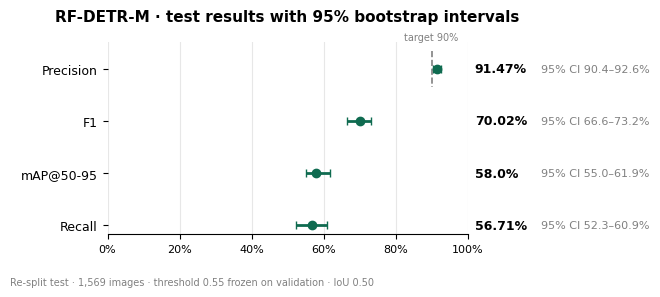

In [27]:
import matplotlib.pyplot as plt

# Test results with 95% bootstrap intervals (in %)
results = [  # (metric, value, ci_low, ci_high, label)
    ("Precision", 91.47, 90.4, 92.6, "91.47%"),
    ("F1",        70.02, 66.6, 73.2, "70.02%"),
    ("mAP@50-95", 58.0,  55.0, 61.9, "58.0%"),
    ("Recall",    56.71, 52.3, 60.9, "56.71%"),
]

fig, ax = plt.subplots(figsize=(7.5, 3))
for y, (name, v, lo, hi, lab) in enumerate(results):
    ax.errorbar(v, y, xerr=[[v - lo], [hi - v]], fmt="o", color="#0f6b50",
                capsize=3, markersize=6, elinewidth=2)
    ax.annotate(lab, xy=(1.02, y), xycoords=("axes fraction", "data"),
                va="center", fontsize=9, fontweight="bold")
    ax.annotate(f"95% CI {lo:.1f}–{hi:.1f}%", xy=(1.02, y), xycoords=("axes fraction", "data"),
                xytext=(48, 0), textcoords="offset points", va="center", fontsize=8, color="gray")

ax.plot([90, 90], [-0.35, 0.35], "--", color="gray", lw=1.2)
ax.text(90, -0.55, "target 90%", ha="center", fontsize=7, color="gray")
ax.set_yticks(range(len(results))); ax.set_yticklabels([r[0] for r in results], fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 20)); ax.set_xticklabels([f"{t}%" for t in range(0, 101, 20)], fontsize=8)
ax.grid(axis="x", alpha=0.3)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.set_title("RF-DETR-M · test results with 95% bootstrap intervals", fontsize=11, fontweight="bold", pad=15)
fig.text(0.01, 0.01, "Re-split test · 1,569 images · threshold 0.55 frozen on validation · IoU 0.50",
         fontsize=7, color="gray")

plt.subplots_adjust(left=0.14, right=0.62, bottom=0.18, top=0.82)
fig.savefig("/content/rfdetr_bootstrap.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Visualization

Sample test images with **ground truth** (left) and **RF-DETR-M predictions** at the
frozen threshold 0.55 (right). Images are chosen at random with a fixed seed, so the
same images appear every time the notebook is run.

[2026-10-14 16:30:31] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-14 16:30:31] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-14 16:30:32] [WARNING] rf-detr - Checkpoint has 6 classes but model is configured for 90. Using checkpoint class count (6). Pass num_classes=6 to suppress this warning.
[2026-10-14 16:30:32] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


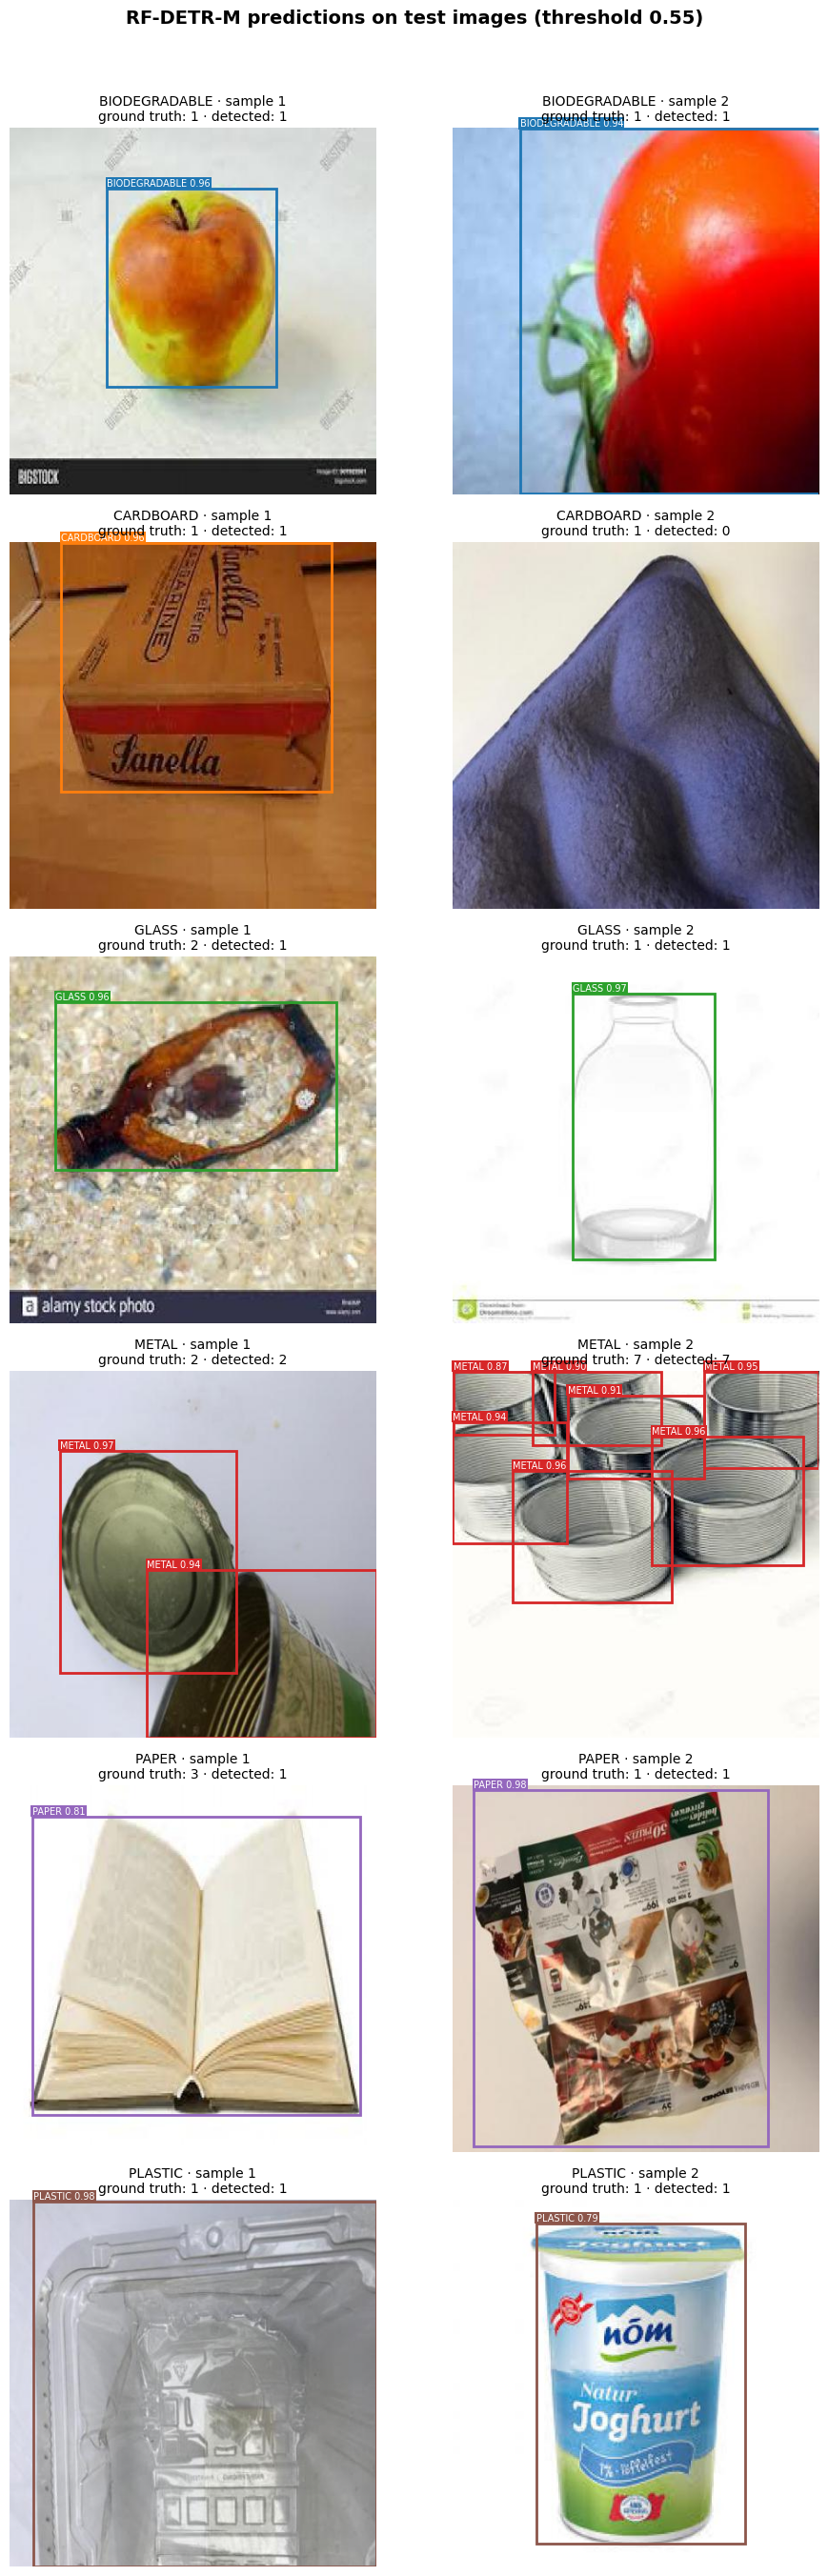

In [32]:
import random, yaml, numpy as np, matplotlib.pyplot as plt, matplotlib.patches as patches
from pathlib import Path
from PIL import Image
from rfdetr import RFDETRMedium

THR, PER_CLASS, SEED = 0.55, 2, 0
DATA, CKPT = Path(DATA), Path(OUT) / "checkpoint_best_total.pth"

names = yaml.safe_load(open(DATA / "data.yaml"))["names"]
if isinstance(names, dict): names = [names[k] for k in sorted(names)]
NAMES = [str(n).upper() for n in names]; NC = len(NAMES)
COLORS = plt.cm.tab10(np.arange(NC))

model = RFDETRMedium(pretrain_weights=str(CKPT))
MODEL_NAMES = [str(n).upper() for n in model.class_names]

def gt_classes(p):
    lbl = DATA / "test" / "labels" / f"{p.stem}.txt"
    if not lbl.exists(): return []
    return [int(l.split()[0]) for l in lbl.read_text().splitlines() if len(l.split()) >= 5]

# ---- pick 2 images per class (no image used twice) ----
imgs = sorted((DATA / "test" / "images").iterdir())
random.Random(SEED).shuffle(imgs)
picked, used = {c: [] for c in range(NC)}, set()
for p in imgs:
    for c in set(gt_classes(p)):
        if len(picked[c]) < PER_CLASS and p not in used:
            picked[c].append(p); used.add(p); break
    if all(len(v) == PER_CLASS for v in picked.values()): break

# ---- plot: each row = one class, 2 images ----
fig, axes = plt.subplots(NC, PER_CLASS, figsize=(5*PER_CLASS, 4.5*NC))
for c in range(NC):
    for k in range(PER_CLASS):
        ax = axes[c, k]; ax.axis("off")
        if k >= len(picked[c]): continue
        p = picked[c][k]
        im = Image.open(p).convert("RGB")
        d = model.predict(im, threshold=THR)
        ax.imshow(im)
        n_pred = 0
        if len(d):
            cls = (np.asarray(d.data["class_name"]) if "class_name" in d.data
                   else [MODEL_NAMES[int(i)] for i in d.class_id])
            for (x1, y1, x2, y2), n, s in zip(d.xyxy, cls, d.confidence):
                n = str(n).upper()
                if n not in NAMES: continue
                j = NAMES.index(n); n_pred += 1
                ax.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, lw=2, edgecolor=COLORS[j]))
                ax.text(x1, y1-3, f"{n} {s:.2f}", fontsize=7, color="white",
                        bbox=dict(facecolor=COLORS[j], edgecolor="none", pad=1))
        ax.set_title(f"{NAMES[c]} · sample {k+1}\nground truth: {len(gt_classes(p))} · detected: {n_pred}",
                     fontsize=10)


fig.suptitle(f"RF-DETR-M predictions on test images (threshold {THR})",
             fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout(rect=(0, 0, 1, 0.985))

## 6. Summary and Conclusion

### Model comparison (re-split test set, 1,569 images)

| Model | Precision | Recall | F1 |
|---|---|---|---|
| SSDLite-MobileNetV3 | 52.54% | 40.78% | 45.92% |
| YOLOv5su | 76.10%| 62.30% | 68.50% |
| YOLO26m | 89.57% | 46.01% | 60.79% |
| **RF-DETR-M** | **91.47%** | 56.71% | **70.02%** |

Precision, recall and F1 use each model's threshold frozen on validation (IoU 0.50).

### Why RF-DETR-M was selected

1. **It is the only model that meets the 90% precision target with statistical confidence.**
   Its 95% bootstrap interval for precision (90.4%–92.6%) lies fully above 90%, and
   99.3% of resamples kept precision ≥ 90%. YOLO26m's interval (88.3%–90.8%) includes values below the target.
2. **It has the best overall detection quality**: highest mAP@50-95 (58.0%, 95% CI 55.0%–61.9%)
   and highest F1 (70.02%).
3. **It is the strongest model on the biodegradable class**, which drives the organic-waste alert:
   AP@50 70.70% and AP@50-95 42.03%, the highest of all four models, with precision 90.67%.

High precision matters most for our application: a wrong organic alert sends a load
for diversion unnecessarily, so false alarms are the costliest error.

### Limitations

- **Moderate recall** (56.71% overall, 53.17% for biodegradable): the model misses some objects.
  The confusion matrix shows that most missed detections are biodegradable items
  predicted as background, so the measured organic share of a load may be underestimated.
- **No validation-loss curve**: validation loss was not logged during training, so training
  behaviour was assessed with validation mAP and the test-set evaluation.


### Future work

- Improve recall for the biodegradable class (more organic training images, threshold tuning per class).
- Evaluate all models on a labelled external image set to measure real-world generalization.
- Retrain with `compute_val_loss=True` to report full training/validation learning curves.

### Conclusion

**RF-DETR-M is the best model for Waste to Value.** It is the only model that reliably
meets the 90% precision target, it leads in mAP and F1, and it performs best on the
biodegradable class that the organic-diversion alert depends on. Its main limitation is
moderate recall, which is the priority for the next iteration.